# Topic classification for Southwestern Dinka (`dik_Latn`) on SIB-200

Experiments notebook (Google Colab, T4 GPU). Run top to bottom. Every run is appended to `runs.csv` on Google Drive, so finished runs are skipped if the session restarts.

* **Data:** Dinka portion of SIB-200 (Adelani et al., 2024), built on Flores-200. Sentences are professional translations of English text; topic labels were annotated in English and projected to Dinka.
* **Dialect:** Flores-200 `dik_Latn` is Southwestern (Rek) Dinka, not Bor.
* **Sections:** 1-2 data, 4 baselines, 5 BiLSTM, 6-7 transformer fine-tuning, 8 results, 9 error analysis, 10 export, 12 transfer experiments, 13 Bor probe (not completed).
* Results and discussion: see `README.md` and the project report.

## 0. Setup

In [5]:
!pip -q install sentencepiece huggingface_hub

In [6]:
import os, re, json, random, unicodedata, time, sys, shutil
import numpy as np, pandas as pd, torch

try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = "/content/drive/MyDrive/dinka_sib200"
except ImportError:                      # running outside Colab
    OUT = "./dinka_sib200"
for sub in ["preds", "deploy", "models"]:
    os.makedirs(f"{OUT}/{sub}", exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "<< WARNING: no GPU. Runtime > Change runtime type > T4 GPU >>")

SEEDS = [0, 1, 2]                        # more seeds = less noise, more time

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

import transformers, sklearn
env = {"torch": torch.__version__, "transformers": transformers.__version__, "sklearn": sklearn.__version__, "python": sys.version.split()[0]}
json.dump(env, open(f"{OUT}/environment.json", "w"), indent=1); print(env)

Mounted at /content/drive
device: cuda Tesla T4
{'torch': '2.11.0+cu130', 'transformers': '5.18.0', 'sklearn': '1.6.1', 'python': '3.13.15'}


## 1. Load data (SIB-200, Dinka `dik_Latn`)

In [7]:
BASE = "https://raw.githubusercontent.com/dadelani/sib-200/main/data/annotated/"
TARGET = "dik_Latn"          # Southwestern Dinka (Flores-200 variety), NOT Bor

def _read(lang, split):
    df = pd.read_csv(f"{BASE}{lang}/{split}.tsv", sep="\t", quoting=3)    # quoting=3: do not treat quotes specially
    df["text"] = df["text"].astype(str).map(lambda t: unicodedata.normalize("NFC", t).strip())
    return df

raw = {s: _read(TARGET, s) for s in ["train", "dev", "test"]}
LABELS = sorted(raw["train"]["category"].unique())
L2I = {l: i for i, l in enumerate(LABELS)}
D = {}

def get(lang):
    """Return {'train','dev','test'} DataFrames for a SIB-200 language with columns index_id, category, text, y, lang."""
    if lang not in D:
        D[lang] = {s: (raw[s] if lang == TARGET else _read(lang, s)).copy() for s in ["train", "dev", "test"]}
        for df in D[lang].values():
            df["y"] = df["category"].map(L2I)
            assert df["y"].notna().all(), "unknown label"
            df["y"] = df["y"].astype(int)
            df["lang"] = lang
    return D[lang]

def split_df(lang, split):
    return get(lang)[split].reset_index(drop=True)

train, dev, test = split_df(TARGET, "train"), split_df(TARGET, "dev"), split_df(TARGET, "test")
eng = pd.concat(get("eng_Latn").values())
ENG = dict(zip(eng.index_id, eng.text))          # English original of every sentence (for error analysis)

print(LABELS)
print(len(train), len(dev), len(test))
train.head(3)

['entertainment', 'geography', 'health', 'politics', 'science/technology', 'sports', 'travel']
701 99 204


,index_id,category,text,y,lang
0,431,geography,Pan cɔl Turkey aci piu war adekdiet guɔ̈l piny...,1,dik_Latn
1,403,science/technology,"War gɔl toŋ rot kɔc ake ye cath wëric, na la k...",4,dik_Latn
2,1592,science/technology,"Na ɔ̈n lä ŋïïny kaŋ pän Greek dhukpïny, gɔ̈ kɔ...",4,dik_Latn


## 2. Data inspection

                    train  dev  test
category                            
science/technology    176   25    51
travel                138   20    40
politics              102   14    30
sports                 85   12    25
health                 77   11    22
entertainment          65    9    19
geography              58    8    17 

words per sentence (train): {'count': 701.0, 'mean': 23.3, 'std': 9.5, 'min': 5.0, '25%': 17.0, '50%': 22.0, '75%': 28.0, 'max': 125.0}
duplicate texts in train: 0
identical text in train AND test: 0
non-ASCII characters: ¥(U+00A5) Ä(U+00C4) Ë(U+00CB) Ü(U+00DC) ã(U+00E3) ä(U+00E4) é(U+00E9) ë(U+00EB) ï(U+00EF) ö(U+00F6) ú(U+00FA) ü(U+00FC) ğ(U+011F) İ(U+0130) Ŋ(U+014A) ŋ(U+014B) Ɣ(U+0194) ɔ(U+0254) ɛ(U+025B) ɣ(U+0263) ̈(U+0308) ε(U+03B5) –(U+2013) —(U+2014) “(U+201C) ”(U+201D) …(U+2026)


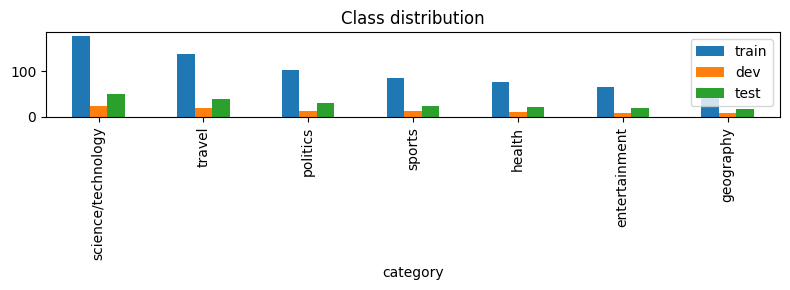

In [8]:
import matplotlib.pyplot as plt

counts = pd.DataFrame({"train": train.category.value_counts(), "dev": dev.category.value_counts(), "test": test.category.value_counts()})
print(counts, "\n")
print("words per sentence (train):", train.text.str.split().str.len().describe().round(1).to_dict())
print("duplicate texts in train:", train.text.duplicated().sum())
print("identical text in train AND test:", len(set(train.text) & set(test.text)))
nonascii = sorted({c for c in "".join(train.text) if ord(c) > 127})
print("non-ASCII characters:", " ".join(f"{c}(U+{ord(c):04X})" for c in nonascii))
counts.plot.bar(figsize=(8, 3)); plt.title("Class distribution"); plt.tight_layout(); plt.show()

A sample of training sentences next to their English source text (`ENG[index_id]`), used to check translations and labels by eye.

In [9]:
for _, r in train.sample(10, random_state=1).iterrows():
    print(f"[{r.category}]\n  DIK: {r.text}\n  ENG: {ENG[r.index_id]}\n")

[travel]
  DIK: piiny tɔ̈u thïn dhɛ̈l pïu aya tɛ̈ pɔth ye kɔc la rëër thïn e lɔ̈ŋ.
  ENG: Inland waterways can be a good theme to base a holiday around.

[travel]
  DIK: Kɔc tourist alëu bïk ɣɔ̈n juëc piny neem pan ci rɔt yök ku kek alëu bïk tak be ya piny tök yen tɔ̈u kek ke nhïm thïn.
  ENG: Tourists may visit different landmarks of a particular country or they may simply opt to focus on just one area.

[health]
  DIK: Dek mɔ̈u amäth. Mɔ̈u akɔ̈c thöŋ gup tɛ̈ loi thok, ku ŋïcŋïc adan ye dek ake riil tör
  ENG: Drink alcoholic drinks with moderation. Alcohol affects everyone differently, and knowing your limit is very important.

[health]
  DIK: Run juec cibak go kɔc pan cɔl Rome wal guir kujɔlke kɔc nyuoth kajuec ŋic kek akol
  ENG: Over multiple centuries, the Roman empire led to great gains in the field of medicine and formed much of the knowledge we know today.

[health]
  DIK: Arias aci yok ke laŋ guop tuany thin kor, yen e raan lui ke ye minister maktab bεny baai ic.
  ENG: Arias

## 3. Run logging helpers

In [10]:
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

RUNS = f"{OUT}/runs.csv"
def runs_df(): return pd.read_csv(RUNS) if os.path.exists(RUNS) else pd.DataFrame()
def is_done(key):
    r = runs_df()
    return len(r) > 0 and key in set(r["key"])
def mf1(y, p): return f1_score(y, p, average="macro")

def log_run(key, exp, seed, dev_f1, test_pred, hparams=""):
    """Append one run to runs.csv and save its test predictions to preds/<key>.csv."""
    row = dict(key=key, exp=exp, seed=seed, dev_macro_f1=dev_f1, test_macro_f1=mf1(test.y, test_pred),
               test_acc=accuracy_score(test.y, test_pred), hparams=hparams)
    pd.concat([runs_df(), pd.DataFrame([row])]).to_csv(RUNS, index=False)
    pd.DataFrame({"index_id": test.index_id, "gold": test.category, "pred": [LABELS[i] for i in test_pred]}).to_csv(f"{OUT}/preds/{key}.csv", index=False)
    print(f"{key}: dev macro-F1 {dev_f1:.4f} | test macro-F1 {row['test_macro_f1']:.4f} | test acc {row['test_acc']:.4f}")

## 4. Baselines
Majority class (sanity floor) and TF-IDF + logistic regression. Hyper-parameters are chosen on **dev**, never on test.

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier

# majority class
key = "majority__s0"
if not is_done(key):
    d = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(train), 1)), train.y)
    log_run(key, "majority", 0, mf1(dev.y, d.predict(np.zeros((len(dev), 1)))), d.predict(np.zeros((len(test), 1))))

def tfidf_run(exp, analyzer, ngram, C):
    key = f"{exp}__s0"
    if is_done(key): return
    clf = make_pipeline(TfidfVectorizer(analyzer=analyzer, ngram_range=ngram, sublinear_tf=True, lowercase=True),
                        LogisticRegression(max_iter=3000, C=C, class_weight="balanced"))
    clf.fit(train.text, train.y)
    log_run(key, exp, 0, mf1(dev.y, clf.predict(dev.text)), clf.predict(test.text), f"{analyzer} {ngram} C={C}")

tfidf_run("tfidf_word_1-2_C10", "word", (1, 2), 10)
for ng in [(2, 5), (1, 4), (3, 6)]:
    for C in [1, 10, 100]:
        tfidf_run(f"tfidf_char_{ng[0]}-{ng[1]}_C{C}", "char_wb", ng, C)

## 5. BiLSTM trained from scratch
Word-level tokens, random embeddings (700 sentences are far too few to train useful embeddings, which is the point of this experiment), bidirectional LSTM, max-pool over time, class-weighted loss, word dropout.

In [12]:
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pad_sequence
from collections import Counter

TOK = re.compile(r"[^\s.,;:!?\"“”‘’()\[\]/]+")
def toks(t): return TOK.findall(t.lower())
cnt = Counter(w for t in train.text for w in toks(t))
vocab = ["<pad>", "<unk>"] + sorted(cnt)
w2i = {w: i for i, w in enumerate(vocab)}
def enc_w(t): return [w2i.get(w, 1) for w in toks(t)] or [1]
print("vocab size:", len(vocab))

class BiLSTM(nn.Module):
    def __init__(self, V, n_cls, E=128, H=128, drop=0.5):
        super().__init__()
        self.emb = nn.Embedding(V, E, padding_idx=0)
        self.lstm = nn.LSTM(E, H, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(drop); self.fc = nn.Linear(2 * H, n_cls)
    def forward(self, x):
        lens = (x != 0).sum(1).cpu()
        packed = pack_padded_sequence(self.drop(self.emb(x)), lens, batch_first=True, enforce_sorted=False)
        h, _ = self.lstm(packed)
        h, _ = pad_packed_sequence(h, batch_first=True, padding_value=-1e9)
        return self.fc(self.drop(h.max(1).values))

def batchify(seqs):
    return pad_sequence([torch.tensor(s) for s in seqs], batch_first=True, padding_value=0).to(DEVICE)

def run_bilstm(exp, seed, E=128, H=128, drop=0.5, lr=2e-3, epochs=40, bs=32, wdrop=0.1):
    key = f"{exp}__s{seed}"
    if is_done(key): return
    set_seed(seed)
    Xtr, Xdv, Xte = [[enc_w(t) for t in d.text] for d in (train, dev, test)]
    ytr = train.y.values
    model = BiLSTM(len(vocab), len(LABELS), E, H, drop).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    cw = torch.tensor(len(ytr) / (len(LABELS) * np.bincount(ytr, minlength=len(LABELS))), dtype=torch.float).to(DEVICE)
    lossf = nn.CrossEntropyLoss(weight=cw)

    @torch.no_grad()
    def predict(X):
        model.eval()
        return torch.cat([model(batchify(X[i:i + 64])).argmax(-1).cpu() for i in range(0, len(X), 64)]).numpy()

    best_f, best_pred = -1, None
    for ep in range(epochs):
        model.train(); perm = np.random.permutation(len(Xtr))
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            xs = [[1 if random.random() < wdrop else w for w in Xtr[j]] for j in b]       # word dropout -> teaches <unk>
            loss = lossf(model(batchify(xs)), torch.tensor(ytr[b]).to(DEVICE))
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        f = mf1(dev.y, predict(Xdv))
        if f > best_f: best_f, best_pred = f, predict(Xte)
    log_run(key, exp, seed, best_f, best_pred, f"E={E} H={H} drop={drop} lr={lr} ep<= {epochs}")

for s in SEEDS:
    run_bilstm("bilstm_scratch", s)

vocab size: 3963


## 6. Transformer fine-tuning code
`model_def.py` is written to Drive (and is the same file the Colab demo uses). Architecture: pretrained encoder -> mean-pool over tokens -> dropout -> linear layer over the 7 topics.

In [13]:
MODEL_DEF = r'''"""Model definition + inference helper shared by the training notebook and the Gradio app."""
import json
import os
import unicodedata

import torch
import torch.nn as nn
from transformers import AutoConfig, AutoModel, AutoTokenizer


class Clf(nn.Module):
    """Pretrained encoder -> mean pooling -> dropout -> linear layer.

    nllb=True keeps only the ENCODER of an NLLB (M2M100) seq2seq model.
    freeze_emb=True freezes the (huge) token-embedding matrix.
    """

    def __init__(self, name, n_labels, nllb=False, freeze_emb=False, drop=0.1, backbone=None):
        super().__init__()
        full = backbone if backbone is not None else AutoModel.from_pretrained(name)
        self.enc = full.get_encoder() if nllb else full
        if freeze_emb:
            for p in self.enc.get_input_embeddings().parameters():
                p.requires_grad = False
        cfg = self.enc.config
        hid = getattr(cfg, "hidden_size", None) or cfg.d_model
        self.drop = nn.Dropout(drop)
        self.head = nn.Linear(hid, n_labels)

    def forward(self, ids, mask):
        h = self.enc(input_ids=ids, attention_mask=mask).last_hidden_state
        m = mask.unsqueeze(-1).to(h.dtype)
        pooled = (h * m).sum(1) / m.sum(1).clamp(min=1)
        return self.head(self.drop(pooled))


def encode(tok, texts, lang=None, maxlen=128, nllb=False):
    """Tokenise a list of strings (NFC-normalised). For NLLB the source-language tag is set first."""
    if nllb and lang:
        tok.src_lang = lang
    texts = [unicodedata.normalize("NFC", str(t)).strip() for t in texts]
    return tok(texts, truncation=True, max_length=maxlen)["input_ids"]


def collate(batch_ids, pad_id, device):
    L = max(len(x) for x in batch_ids)
    ids = torch.full((len(batch_ids), L), pad_id, dtype=torch.long)
    mask = torch.zeros((len(batch_ids), L), dtype=torch.long)
    for i, x in enumerate(batch_ids):
        ids[i, : len(x)] = torch.tensor(x)
        mask[i, : len(x)] = 1
    return ids.to(device), mask.to(device)


def load_predictor(path, device=None):
    """Load meta.json + weights.pt from `path`; return predict(texts, lang=None) -> list of {label: prob}."""
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    meta = json.load(open(os.path.join(path, "meta.json")))
    nllb = meta["nllb"]
    tok = AutoTokenizer.from_pretrained(meta["tokenizer"], **({"src_lang": meta["src_lang"]} if nllb else {}))
    backbone = AutoModel.from_config(AutoConfig.from_pretrained(meta["name"]))  # architecture only, no download of weights
    model = Clf(meta["name"], len(meta["labels"]), nllb=nllb, backbone=backbone)
    sd = torch.load(os.path.join(path, "weights.pt"), map_location="cpu")
    model.load_state_dict({k: (v.float() if v.is_floating_point() else v) for k, v in sd.items()})
    model.to(device).eval()
    pad = tok.pad_token_id

    @torch.no_grad()
    def predict(texts, lang=None):
        out = []
        for i in range(0, len(texts), 32):
            chunk = texts[i : i + 32]
            ids, mask = collate(encode(tok, chunk, lang or meta["src_lang"], meta["maxlen"], nllb), pad, device)
            probs = torch.softmax(model(ids, mask).float(), -1).cpu().tolist()
            out += [dict(zip(meta["labels"], p)) for p in probs]
        return out

    return predict
'''
open(f"{OUT}/deploy/model_def.py", "w").write(MODEL_DEF)

3318

In [14]:
import torch.nn as nn
sys.path.insert(0, f"{OUT}/deploy")
from model_def import Clf, encode, collate
from transformers import AutoTokenizer, get_linear_schedule_with_warmup

_tok = {}
def get_tok(name, nllb):
    if name not in _tok:
        _tok[name] = AutoTokenizer.from_pretrained(name, **({"src_lang": TARGET} if nllb else {}))
    return _tok[name]

def encode_df(tok, df, maxlen, nllb):
    df = df.reset_index(drop=True); ids = [None] * len(df)
    for lang, g in df.groupby("lang"):
        for i, e in zip(g.index, encode(tok, g.text.tolist(), lang, maxlen, nllb)): ids[i] = e
    return ids

def run_transformer(exp, name, seed, train_df, dev_df, test_df=None, epochs=20, lr=2e-5, head_lr=1e-3, bs=16, nllb=False,
                    freeze_emb=False, maxlen=128, warmup=0.1, patience=6, save_dir=None):
    test_df = test if test_df is None else test_df
    key = f"{exp}__s{seed}"
    have_log = is_done(key)
    if have_log and (save_dir is None or os.path.exists(f"{save_dir}/weights.pt")):
        print("skip", key); return
    set_seed(seed); tok = get_tok(name, nllb)
    Xtr, Xdv, Xte = [encode_df(tok, d, maxlen, nllb) for d in (train_df, dev_df, test_df)]
    ytr, ydv = train_df.y.values, dev_df.y.values
    model = Clf(name, len(LABELS), nllb, freeze_emb).to(DEVICE)
    opt = torch.optim.AdamW([{"params": [p for p in model.enc.parameters() if p.requires_grad], "lr": lr},
                             {"params": model.head.parameters(), "lr": head_lr}], weight_decay=0.01)
    steps = epochs * int(np.ceil(len(Xtr) / bs))
    sch = get_linear_schedule_with_warmup(opt, int(warmup * steps), steps)
    use_amp = DEVICE == "cuda"
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    cw = torch.tensor(len(ytr) / (len(LABELS) * np.bincount(ytr, minlength=len(LABELS))), dtype=torch.float).to(DEVICE)
    lossf = nn.CrossEntropyLoss(weight=cw); pad = tok.pad_token_id

    @torch.no_grad()
    def predict(X):
        model.eval(); out = []
        for i in range(0, len(X), 64):
            ids, m = collate(X[i:i + 64], pad, DEVICE)
            with torch.autocast(DEVICE, dtype=torch.float16, enabled=use_amp):
                out.append(model(ids, m).float().argmax(-1).cpu())
        return torch.cat(out).numpy()

    best_f, best_ep, best_pred, best_state, bad, t0 = -1, -1, None, None, 0, time.time()
    for ep in range(epochs):
        model.train(); perm = np.random.permutation(len(Xtr)); tl = 0.0
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            ids, m = collate([Xtr[j] for j in b], pad, DEVICE); y = torch.tensor(ytr[b]).to(DEVICE)
            with torch.autocast(DEVICE, dtype=torch.float16, enabled=use_amp):
                logits = model(ids, m)
            loss = lossf(logits.float(), y)
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(opt); scaler.update(); sch.step()
            tl += loss.item() * len(b)
        f = mf1(ydv, predict(Xdv))
        print(f"  ep {ep:2d} loss {tl / len(Xtr):.3f} dev macro-F1 {f:.4f}  ({time.time() - t0:.0f}s)")
        if f > best_f:
            best_f, best_ep, best_pred, bad = f, ep, predict(Xte), 0
            if save_dir: best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    if not have_log:
        log_run(key, exp, seed, best_f, best_pred, f"{name} lr={lr} head_lr={head_lr} bs={bs} freeze_emb={freeze_emb} best_ep={best_ep}")
    if save_dir:
        os.makedirs(save_dir, exist_ok=True)
        torch.save({k: (v.half() if v.is_floating_point() else v) for k, v in best_state.items()}, f"{save_dir}/weights.pt")
        json.dump({"name": name, "tokenizer": name, "nllb": nllb, "labels": LABELS, "maxlen": maxlen, "src_lang": TARGET, "exp": exp},
                  open(f"{save_dir}/meta.json", "w"), indent=1)
    del model, opt; torch.cuda.empty_cache()

## 7. Transformer experiments
* **xlmr_base**: XLM-R base (multilingual; to my knowledge Dinka is not among its 100 pretraining languages).
* **nllb600m_encoder**: encoder of NLLB-200-distilled-600M. NLLB was trained to translate Dinka, so its encoder has seen the language. This is the main hypothesis.
* Set `RUN_ABLATIONS = True` for extra rows (learning rate, unfrozen embeddings) if you have time.

Weights of the **seed-0** run of each model are saved to Drive (`models/<exp>`) for deployment.

In [15]:
CONFIGS = {
    "xlmr_base":        dict(name="xlm-roberta-base", nllb=False, freeze_emb=False, lr=2e-5, epochs=20),
    "nllb600m_encoder": dict(name="facebook/nllb-200-distilled-600M", nllb=True, freeze_emb=True, lr=3e-5, epochs=20),
}
RUN_ABLATIONS = False
if RUN_ABLATIONS:
    CONFIGS["xlmr_base_lr5e-5"] = dict(CONFIGS["xlmr_base"], lr=5e-5)
    CONFIGS["nllb600m_unfrozen_emb"] = dict(CONFIGS["nllb600m_encoder"], freeze_emb=False)   # may run out of GPU memory on T4

# --- new ablations ---
CONFIGS["xlmr_frozen_emb"] = dict(CONFIGS["xlmr_base"], freeze_emb=True)     # does freezing embeddings explain part of the XLM-R vs NLLB gap?
CONFIGS["nllb600m_lr5e-5"] = dict(CONFIGS["nllb600m_encoder"], lr=5e-5)      # is NLLB sensitive to the learning rate?

for exp, cfg in CONFIGS.items():
    for s in SEEDS:
        print(f"=== {exp} seed {s}")
        run_transformer(exp, seed=s, train_df=train, dev_df=dev, save_dir=(f"{OUT}/models/{exp}" if s == 0 else None), **cfg)

=== xlmr_base seed 0
skip xlmr_base__s0
=== xlmr_base seed 1
skip xlmr_base__s1
=== xlmr_base seed 2
skip xlmr_base__s2
=== nllb600m_encoder seed 0
skip nllb600m_encoder__s0
=== nllb600m_encoder seed 1
skip nllb600m_encoder__s1
=== nllb600m_encoder seed 2
skip nllb600m_encoder__s2
=== xlmr_frozen_emb seed 0
skip xlmr_frozen_emb__s0
=== xlmr_frozen_emb seed 1
skip xlmr_frozen_emb__s1
=== xlmr_frozen_emb seed 2
skip xlmr_frozen_emb__s2
=== nllb600m_lr5e-5 seed 0
skip nllb600m_lr5e-5__s0
=== nllb600m_lr5e-5 seed 1
skip nllb600m_lr5e-5__s1
=== nllb600m_lr5e-5 seed 2
skip nllb600m_lr5e-5__s2


If the NLLB run hits `CUDA out of memory`: restart the runtime, lower `bs` (add `bs=8` to the NLLB config), re-run. Finished runs are skipped.

## 8. Results table (mean ± std over seeds; model selection is by **dev** macro-F1)

In [16]:
def summary():
    r = runs_df()
    s = r.groupby("exp").agg(runs=("seed", "count"), dev_f1=("dev_macro_f1", "mean"), test_f1=("test_macro_f1", "mean"),
                             test_f1_std=("test_macro_f1", "std"), test_acc=("test_acc", "mean")).fillna(0).round(4)
    return s.sort_values("dev_f1", ascending=False)

S = summary(); S.to_csv(f"{OUT}/results_table.csv"); S

,runs,dev_f1,test_f1,test_f1_std,test_acc
exp,,,,,
transfer_eng_zeroshot,3,0.8468,0.6346,0.0167,0.6422
transfer_luo_zeroshot,3,0.8068,0.6744,0.0182,0.6863
nllb600m_encoder,3,0.7780,0.7196,0.0136,0.7320
nllb600m_lr5e-5,3,0.7753,0.7309,0.0008,0.7435
tfidf_char_3-6_C10,1,0.7714,0.7108,0.0000,0.7500
tfidf_char_2-5_C10,1,0.7640,0.7236,0.0000,0.7598
tfidf_char_3-6_C1,1,0.7619,0.7186,0.0000,0.7500
tfidf_char_3-6_C100,1,0.7614,0.7049,0.0000,0.7451
transfer_nus_zeroshot,3,0.7606,0.6339,0.0109,0.6520


In [17]:
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

full = pd.concat([train, dev]).reset_index(drop=True)
pipe = make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True),
                     LogisticRegression(max_iter=3000, C=10, class_weight="balanced"))
sc = []
for a, b in StratifiedKFold(5, shuffle=True, random_state=0).split(full.text, full.y):
    pipe.fit(full.text.iloc[a], full.y.iloc[a])
    sc.append(mf1(full.y.iloc[b], pipe.predict(full.text.iloc[b])))
print(np.round(sc, 3), "mean", round(np.mean(sc), 3), "std", round(np.std(sc), 3))
print("for comparison: dev 0.764, test 0.724")

[0.707 0.669 0.734 0.662 0.619] mean 0.678 std 0.04
for comparison: dev 0.764, test 0.724


In [18]:
gold = test.y.values

def load_pred(exp, seed=0):
    return pd.read_csv(f"{OUT}/preds/{exp}__s{seed}.csv").pred.map(L2I).values

def paired(a, b, n=2000):
    pa, pb = load_pred(a), load_pred(b)
    rng = np.random.default_rng(0)
    d = []
    for _ in range(n):
        ix = rng.integers(0, len(gold), len(gold))
        d.append(mf1(gold[ix], pa[ix]) - mf1(gold[ix], pb[ix]))
    return np.mean(d), np.percentile(d, [2.5, 97.5])

pairs = [("nllb600m_encoder", "tfidf_char_2-5_C10"),
         ("nllb600m_encoder", "xlmr_base"),
         ("tfidf_char_2-5_C10", "bilstm_scratch")]
for a, b in pairs:
    m, ci = paired(a, b)
    print(f"{a} - {b}: {m:+.3f}, 95% CI [{ci[0]:+.3f}, {ci[1]:+.3f}]")

nllb600m_encoder - tfidf_char_2-5_C10: -0.001, 95% CI [-0.076, +0.073]
nllb600m_encoder - xlmr_base: +0.157, 95% CI [+0.074, +0.236]
tfidf_char_2-5_C10 - bilstm_scratch: +0.124, 95% CI [+0.057, +0.191]


## 9. Error analysis
Picks the best main model **by dev score**, shows the confusion matrix, per-class scores, a bootstrap confidence interval (the test set has only 204 sentences, so scores are noisy) and exports every mistake to a CSV for you to annotate in Dinka.

best by dev: nllb600m_encoder
                    precision    recall  f1-score   support

     entertainment      0.692     0.474     0.562        19
         geography      0.667     0.706     0.686        17
            health      0.789     0.682     0.732        22
          politics      0.846     0.733     0.786        30
science/technology      0.714     0.784     0.748        51
            sports      0.769     0.800     0.784        25
            travel      0.717     0.825     0.767        40

          accuracy                          0.740       204
         macro avg      0.742     0.715     0.724       204
      weighted avg      0.743     0.740     0.737       204



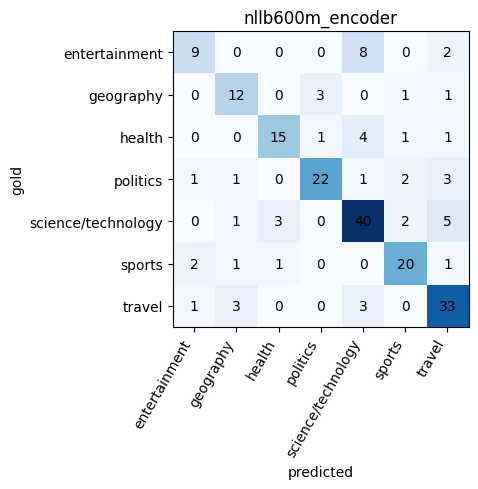

test macro-F1 0.724, 95% bootstrap CI [0.646, 0.784]
wrong in all 15 main models: 15 of 204
53 errors saved to errors_to_annotate.csv


,index_id,gold,pred,dik_text,english,wrong_in_all_models,error_type,my_notes_(dialect? translation? ambiguous? model?)
5,452,science/technology,travel,"ku të ye ke nuɛ̈ɛ̈t thïn, ku të ye të ca täk y...",Interactive design requires that you re-assess...,False,,
7,1360,science/technology,health,Akut kɔ̈ɔ̈r εe yic la kɔ̈ɔ̈rdit kadiak keye rö...,Prides are made up of one to three related adu...,False,,
11,1555,science/technology,sports,Nä cök älɔn ë yë gëëk yä tou kä yë tïm cï këk ...,Although wagonways merely consisted of paralle...,False,,
19,1519,science/technology,health,Aleu bi kɔc ŋic lon luel raan lueth tä cita ye...,"In particular, it is claimed that one can dete...",False,,
24,1024,science/technology,geography,Ku kënnë akëc rɔt det lon ëë ländït ye kɔc lik...,This not only confirms that at least some dino...,False,,
32,1254,science/technology,health,Kaka cätnhom a rot mät bïk ke la duɔlduöl loi ...,The two compounds react with one another to fo...,False,,
38,584,science/technology,travel,Kɔ̈ɔ̈c äcï läj gɔl kek lön madhara käcip bïk k...,Humans have been making and using lenses for m...,False,,
39,1589,science/technology,travel,"Äce yën ë tök, athëm, ku äthëm ë kë yë löi bë ...","It isn’t alone though, experimentation, and an...",False,,


In [19]:
main = S[~S.index.str.startswith(("transfer_", "pooled_", "majority"))]
BEST = main.index[0]; print("best by dev:", BEST)
P = lambda exp: pd.read_csv(f"{OUT}/preds/{exp}__s0.csv")
pb = P(BEST); gold = test.y.values; pred = pb.pred.map(L2I).values

print(classification_report(gold, pred, target_names=LABELS, digits=3))
cm = confusion_matrix(gold, pred)
fig, ax = plt.subplots(figsize=(6, 5)); ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(LABELS))); ax.set_yticks(range(len(LABELS)))
ax.set_xticklabels(LABELS, rotation=60, ha="right"); ax.set_yticklabels(LABELS)
for i in range(len(LABELS)):
    for j in range(len(LABELS)): ax.text(j, i, cm[i, j], ha="center", va="center")
ax.set_xlabel("predicted"); ax.set_ylabel("gold"); ax.set_title(BEST); plt.tight_layout(); plt.show()

rng = np.random.default_rng(0)
bs_f1 = [mf1(gold[ix], pred[ix]) for ix in (rng.integers(0, len(gold), len(gold)) for _ in range(1000))]
print(f"test macro-F1 {mf1(gold, pred):.3f}, 95% bootstrap CI [{np.percentile(bs_f1, 2.5):.3f}, {np.percentile(bs_f1, 97.5):.3f}]")

# sentences wrong in EVERY main model (seed 0) = "hard" sentences
wrong = {e: (P(e).pred.map(L2I).values != gold) for e in main.index}
hard = np.all(list(wrong.values()), axis=0)
print("wrong in all", len(wrong), "main models:", hard.sum(), "of", len(gold))

err = pd.DataFrame({"index_id": test.index_id, "gold": test.category, "pred": pb.pred, "dik_text": test.text,
                    "english": [ENG[i] for i in test.index_id], "wrong_in_all_models": hard})[pred != gold]
err["error_type"] = ""; err["my_notes_(dialect? translation? ambiguous? model?)"] = ""
err.to_csv(f"{OUT}/errors_to_annotate.csv", index=False)
print(len(err), "errors saved to errors_to_annotate.csv")
err.head(8)

## 10. Export the model for the demo
`DEPLOY_EXP` defaults to the best transformer by dev score. This model is served in the Colab demo (`demo/Dinka_Demo_Colab.ipynb`); the live Streamlit app serves the TF-IDF model, which is statistically tied with it.

In [20]:
trans = [e for e in S.index if e in CONFIGS and os.path.exists(f"{OUT}/models/{e}/weights.pt")]
DEPLOY_EXP = trans[0]; print("deploying:", DEPLOY_EXP)
for f in ["weights.pt", "meta.json"]:
    shutil.copy(f"{OUT}/models/{DEPLOY_EXP}/{f}", f"{OUT}/deploy/{f}")

from model_def import load_predictor
predict = load_predictor(f"{OUT}/deploy")
for t in test.text.head(3):
    p = predict([t])[0]; print(max(p, key=p.get), "|", t[:90])

deploying: nllb600m_encoder


config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/3.55k [00:00<?, ?B/s]

science/technology | Guop raan εe rot waar bi la mɛ̈t rot thin ku kejal thin
science/technology | Fission bomb alui löŋ eyen riɛl nyai be mat kek nucleus kek protons juëc ku neutrons.
science/technology | Nucleus älä ɣïïc käŋ kë rou - neutrons ku protons.


**Upload the fine-tuned model to the Hugging Face Hub (used by `demo/Dinka_Demo_Colab.ipynb`).**
The live public app in `streamlit_app/` serves the TF-IDF model; the Colab demo serves the fine-tuned NLLB encoder from this Hub repository. Run the next cell to upload `deploy/` (weights + `model_def.py` + `meta.json`) to a model repo.


In [21]:
from huggingface_hub import login, HfApi

try:
    from google.colab import userdata
    login(token=userdata.get("HF_TOKEN"))
except Exception as e:
    print("Colab secret not found, falling back to manual login:", e)
    from huggingface_hub import notebook_login
    notebook_login()

print("files to upload:", os.listdir(f"{OUT}/deploy"))     # expect: model_def.py, weights.pt, meta.json

api = HfApi()
user = api.whoami()["name"]
REPO = f"{user}/dinka-sib200-classifier"
api.create_repo(REPO, repo_type="model", exist_ok=True)
api.upload_folder(folder_path=f"{OUT}/deploy", repo_id=REPO, repo_type="model")
print("uploaded: https://huggingface.co/" + REPO)

files to upload: ['__pycache__', 'weights.pt', 'model_def.py', 'meta.json']
uploaded: https://huggingface.co/slickman-tyrus/dinka-sib200-classifier


## 11. Quick check of the saved predictor on custom text
Replace the placeholder string with your own Dinka sentence.

In [22]:
for t in ["<<paste a Dinka sentence here>>"]:
    p = predict([t])[0]
    print(sorted(p.items(), key=lambda kv: -kv[1])[:3])

[('entertainment', 0.3188445568084717), ('science/technology', 0.28799816966056824), ('politics', 0.12395802140235901)]


## 12. Transfer experiments
**Question:** does training on a related Nilotic language (Nuer `nus_Latn`), a more distant African language (Dholuo `luo_Latn`, Luo/Nilotic, further from Dinka), or English help classify Dinka? Zero-shot rows train only on the source language (model selection uses the *source* dev set, so Dinka is never seen). The pooled row adds Dinka.

Note: SIB-200 is parallel. The same sentences appear in every language, so pooling Dinka + Nuer gives a second surface form of the *same* content, not new content.

In [23]:
SRC = ["nus_Latn", "luo_Latn", "eng_Latn"]
for L in SRC:
    g = get(L)
    assert set(g["train"].index_id).isdisjoint(set(test.index_id)), "leakage!"
    agree = (g["train"].set_index("index_id").category == train.set_index("index_id").category.reindex(g["train"].index_id).values).mean()
    print(L, "train/test disjoint from Dinka test: OK | label agreement with Dinka rows:", round(agree, 3))

TRANSFER_MODEL = DEPLOY_EXP            # or "xlmr_base" / "nllb600m_encoder"
cfg = CONFIGS[TRANSFER_MODEL]
for L in SRC:
    for s in SEEDS:
        print(f"=== transfer_{L[:3]}_zeroshot ({TRANSFER_MODEL}) seed {s}")
        run_transformer(f"transfer_{L[:3]}_zeroshot", seed=s, train_df=split_df(L, "train"), dev_df=split_df(L, "dev"), **cfg)
for s in SEEDS:
    print(f"=== pooled_dik+nus seed {s}")
    run_transformer("pooled_dik+nus", seed=s, train_df=pd.concat([split_df(TARGET, "train"), split_df("nus_Latn", "train")]),
                    dev_df=dev, **cfg)
summary()

nus_Latn train/test disjoint from Dinka test: OK | label agreement with Dinka rows: 1.0
luo_Latn train/test disjoint from Dinka test: OK | label agreement with Dinka rows: 1.0
eng_Latn train/test disjoint from Dinka test: OK | label agreement with Dinka rows: 1.0
=== transfer_nus_zeroshot (nllb600m_encoder) seed 0
skip transfer_nus_zeroshot__s0
=== transfer_nus_zeroshot (nllb600m_encoder) seed 1
skip transfer_nus_zeroshot__s1
=== transfer_nus_zeroshot (nllb600m_encoder) seed 2
skip transfer_nus_zeroshot__s2
=== transfer_luo_zeroshot (nllb600m_encoder) seed 0
skip transfer_luo_zeroshot__s0
=== transfer_luo_zeroshot (nllb600m_encoder) seed 1
skip transfer_luo_zeroshot__s1
=== transfer_luo_zeroshot (nllb600m_encoder) seed 2
skip transfer_luo_zeroshot__s2
=== transfer_eng_zeroshot (nllb600m_encoder) seed 0
skip transfer_eng_zeroshot__s0
=== transfer_eng_zeroshot (nllb600m_encoder) seed 1
skip transfer_eng_zeroshot__s1
=== transfer_eng_zeroshot (nllb600m_encoder) seed 2
skip transfer_eng_ze

,runs,dev_f1,test_f1,test_f1_std,test_acc
exp,,,,,
transfer_eng_zeroshot,3,0.8468,0.6346,0.0167,0.6422
transfer_luo_zeroshot,3,0.8068,0.6744,0.0182,0.6863
nllb600m_encoder,3,0.7780,0.7196,0.0136,0.7320
nllb600m_lr5e-5,3,0.7753,0.7309,0.0008,0.7435
tfidf_char_3-6_C10,1,0.7714,0.7108,0.0000,0.7500
tfidf_char_2-5_C10,1,0.7640,0.7236,0.0000,0.7598
tfidf_char_3-6_C1,1,0.7619,0.7186,0.0000,0.7500
tfidf_char_3-6_C100,1,0.7614,0.7049,0.0000,0.7451
transfer_nus_zeroshot,3,0.7606,0.6339,0.0109,0.6520


## 13. Bor-Dinka probe (optional, not completed)
Planned extension: translate 60 test sentences from English into Bor and compare accuracy on the Southwestern and Bor versions to measure the dialect gap. The template is generated below; the evaluation cell is skipped when `bor_probe_filled.csv` is absent. This was **not completed** for the submitted project and is listed as future work in the report.

In [24]:
probe = test.sample(60, random_state=42)[["index_id", "category", "text"]].rename(columns={"text": "dik_southwestern"})
probe["english"] = [ENG[i] for i in probe.index_id]; probe["bor_translation"] = ""
probe.to_csv(f"{OUT}/bor_probe_template.csv", index=False); print("wrote bor_probe_template.csv")

wrote bor_probe_template.csv


In [25]:
probe_path = f"{OUT}/bor_probe_filled.csv"

if "predict" not in globals():
    print("Skipped: run Section 10 first (it defines predict).")
elif not os.path.exists(probe_path):
    print("Skipped: bor_probe_filled.csv not found. This optional probe needs your Bor translations: "
          "fill the 'bor_translation' column of bor_probe_template.csv and save it under this name.")
else:
    pf = pd.read_csv(probe_path).dropna(subset=["bor_translation"])
    pf = pf[pf["bor_translation"].astype(str).str.strip() != ""]
    if len(pf) == 0:
        print("Skipped: the 'bor_translation' column is empty.")
    else:
        def acc(col):
            out = predict(pf[col].astype(str).tolist())
            return np.mean([max(o, key=o.get) == g for o, g in zip(out, pf.category)])
        print(f"n={len(pf)}  accuracy on Southwestern: {acc('dik_southwestern'):.3f}   on your Bor translations: {acc('bor_translation'):.3f}")

Skipped: bor_probe_filled.csv not found. This optional probe needs your Bor translations: fill the 'bor_translation' column of bor_probe_template.csv and save it under this name.


## 14. Outputs
Written to Drive: `runs.csv`, `results_table.csv`, `preds/`, `errors_to_annotate.csv`, `environment.json`, `models/` and `deploy/`. Model weights are not committed to GitHub; they are on the Hugging Face Hub.